In [2]:
import os
import json
from pathlib import Path
import pandas as pd
from scipy import stats

# Loading Excel file

## Loading QC Released

In [3]:
# Access the Excel file
excel_file_path = r"../QC progress overview - Line 1 COPY2.xlsm"

# List all tabs (sheets) in the Excel file
excel_file = pd.ExcelFile(excel_file_path)
sheet_names = excel_file.sheet_names

# Filter sheets that start with "Overview"
overview_sheets = [name for name in sheet_names if name.startswith("Overview")][:-1]

# Initialize the released_qc list to combine all data
released_qc = []

for sheet in overview_sheets:
    df = pd.read_excel(excel_file_path, sheet_name=sheet, header=None)

    # Extract columns K and L (index 10 and 11, since K is the 11th column)
    if len(df.columns) > 11:
        col_k = df.iloc[:, 10]  # Column K
        col_l = df.iloc[:, 11]  # Column L

        release_header = col_k.iloc[0]
        if release_header != "Release":
            print(f"Sheet '{sheet}' does not have 'Release' in column K and L. Skipping.")
            continue

        # Get all values from row 3 onwards (index 2+, skipping header rows and the anode/cathode row)
        col_k_values = col_k.iloc[3:].dropna().tolist()
        col_l_values = col_l.iloc[3:].dropna().tolist()

        # Combine into a single list for this sheet
        combined_list = col_k_values + col_l_values

        # Add to the master "released_qc" list
        released_qc.extend(combined_list)
    else:
        print("File does not have enough columns (K and L)")

# Print the final released_qc list
print("\n\n=== FINAL RELEASED QC LIST ===")
print(released_qc)
print(f"Total items in released_qc list: {len(released_qc)}")




=== FINAL RELEASED QC LIST ===
['B394', 'B456', 'B463', 'B468', 'B572', 'B578', 'B618', 'B655', 'B669', 'B687', 'B1293', 'B1298', 'B1307', 'B1324', 'B1328', 'B1334', 'B1342', 'B1377', 'B1397', 'B1414', 'B1423', 'B1436', 'B1455', 'B1461', 'B1474', 'B1484', 'B1496', 'B1532', 'B1588', 'B1616', 'B1636', 'B1644', 'B1666', 'B1683', 'B1692', 'B1711', 'B1732', 'B1761', 'B2064', 'B2077', 'B2092', 'B2125', 'B2141', 'B2157', 'B2177', 'B2209', 'B2227', 'B2265', 'B2278', 'B733', 'B757', 'B762', 'B772', 'B897', 'B919', 'B943', 'B974', 'B979', 'B1008', 'B1025', 'B1039', 'B1046', 'B1052', 'B1058', 'B1068', 'B1083', 'B1091', 'B1104', 'B1115', 'B1124', 'B1133', 'B1144', 'B1175', 'B1229', 'B1237', 'B1262', 'B1780', 'B1870', 'B1893', 'B1943', 'B1962', 'B1990', 'B2011', 'B2027', 'B2047', 'B2302', 'B2497', 'B2518', 'B2528', 'B2542', 'B2606', 'B2628', 'B2644', 'B2664', 'B3014', 'B3039', 'B3059', 'B3072', 'B3080', 'B2386', 'B2405', 'B2421', 'B2441', 'B2478', 'B2674', 'B2692', 'B2711', 'B2733', 'B2768', 'B27

## Loading QC Scraped

In [4]:
# Similar process but for columns M, N, O, P with "scraped" header
# Initialize the scraped_qc list to combine all data
scraped_qc = []
anodes = "Anodes"
cathodes = "Cathodes"

for sheet in overview_sheets:
    df = pd.read_excel(excel_file_path, sheet_name=sheet, header=None)

    # Extract columns M, N, O, P (index 12, 13, 14, 15)
    if len(df.columns) > 12:
        col_m = df.iloc[:, 12]  # Column M
        col_n = df.iloc[:, 13]  # Column N

        scraped_header = col_m.iloc[0]
        if scraped_header != "Scraped":
            print(f"Sheet '{sheet}' does not have 'Scraped' in column M. Skipping.")
            continue

        # Get all values from row 3 onwards (index 3+)
        col_m_values = col_m.iloc[3:].dropna().tolist()
        col_n_values = col_n.iloc[3:].dropna().tolist()

        combined_list = col_m_values + col_n_values
        used_columns = "M, N"

        # Check if column O should be used (third row has "anodes" or "cathodes")
        if len(df.columns) > 14:
            third_row_o = df.iloc[2, 14]
            if third_row_o == anodes or third_row_o == cathodes:
                col_o = df.iloc[:, 14]
                col_o_values = col_o.iloc[3:].dropna().tolist()
                combined_list.extend(col_o_values)
                used_columns += ", O"

        # Check if column P should be used (third row has "anodes" or "cathodes")
        if len(df.columns) > 15:
            third_row_p = df.iloc[2, 15]
            if third_row_p == anodes or third_row_p == cathodes:
                col_p = df.iloc[:, 15]
                col_p_values = col_p.iloc[3:].dropna().tolist()
                combined_list.extend(col_p_values)
                used_columns += ", P"

        # Add to the master "scraped_qc" list
        scraped_qc.extend(combined_list)
    else:
        print("File does not have enough columns (M, N)")

# Print the final scraped_qc list
print("\n\n=== FINAL SCRAPED QC LIST ===")
print(scraped_qc)
print(f"Total items in scraped_qc list: {len(scraped_qc)}")





=== FINAL SCRAPED QC LIST ===
['B2110', 'B3135', 'B3234', 'B3259', 'B3282', 'B3313', 'B3810', 'B3834', 'B3908', 'B4140', 'B4141', 'B4147', 'B4148', 'B4149', 'B4156', 'B4157', 'B4253', 'B3095', 'B3233', 'B3248', 'B3591', 'B3771', 'B3796', 'B4008', 'B4061', 'B4076', 'B4089', 'B4090', 'B4091', 'B4181', 'B5180', 'B5320', 'B5366', 'B5174', 'B4319', 'B4343', 'B4396', 'B4420', 'B4452', 'B4598', 'B4599', 'B4787', 'B4889', 'B4918', 'B4508', 'B4656', 'B5006', 'B4731', 'B5376', 'B5573', 'B5816', 'B6475', 'B6490', 'B6685', 'B6195', 'B6207', 'B6233', 'B6356', 'B6381', 'B6601', 'B5892', 'B5832', 'B5965', 'B6137', 'B6498', 'B6685', 'B7462', 'B7651', 'B7623', 'B7611', 'B7962', 'B6703', 'B7208', 'B7970', 'B7993', 'B7967', 'B7088', 'B7588', 'B7605', 'B7902', 'B8351', 'B8364', 'B8469', 'B8512', 'B8520', 'B8869', 'B8913', 'B8933', 'B9349', 'B9566', 'B8477']
Total items in scraped_qc list: 91


## Data cleaning

In [5]:
# Remove duplicates and sort both lists (create new cleaned arrays)
print("=== REMOVING DUPLICATES AND SORTING ===\n")

# Helper function to extract number from items like "B123"
def extract_number(item):
    try:
        return int(item[1:])  # Extract everything after the first character
    except (ValueError, IndexError):
        return float('inf')  # Put non-numeric items at the end

# Function to find duplicates
def find_duplicates(lst):
    seen = set()
    duplicates = []
    for item in lst:
        if item in seen and item not in duplicates:
            duplicates.append(item)
        seen.add(item)
    return duplicates

# Process released_qc list
released_qc_original_count = len(released_qc)
released_qc_dups = find_duplicates(released_qc)
released_qc_cleaned = sorted(list(set(released_qc)), key=extract_number)
released_qc_unique_count = len(released_qc_cleaned)
released_qc_duplicates_count = released_qc_original_count - released_qc_unique_count

print(f"RELEASED QC LIST:")
print(f"  Original count: {released_qc_original_count}")
print(f"  Unique count: {released_qc_unique_count}")
if released_qc_duplicates_count > 0:
    print(f"  ⚠️ DUPLICATES FOUND: {released_qc_duplicates_count}")
    print(f"  Duplicate items: {released_qc_dups}")
else:
    print(f"  ✓ No duplicates found")

# Process scraped_qc list
scraped_qc_original_count = len(scraped_qc)
scraped_qc_dups = find_duplicates(scraped_qc)
scraped_qc_cleaned = sorted(list(set(scraped_qc)), key=extract_number)
scraped_qc_unique_count = len(scraped_qc_cleaned)
scraped_qc_duplicates_count = scraped_qc_original_count - scraped_qc_unique_count

print(f"SCRAPED QC LIST:")
print(f"  Original count: {scraped_qc_original_count}")
print(f"  Unique count: {scraped_qc_unique_count}")
if scraped_qc_duplicates_count > 0:
    print(f"  ⚠️ DUPLICATES FOUND: {scraped_qc_duplicates_count}")
    print(f"  Duplicate items: {scraped_qc_dups}")
else:
    print(f"  ✓ No duplicates found")

# Check for common elements between released_qc_cleaned and scraped_qc_cleaned
print("=== CROSS-LIST CHECK ===")
common_elements = list(set(released_qc_cleaned) & set(scraped_qc_cleaned))
if common_elements:
    print(f"⚠️ FOUND {len(common_elements)} element(s) in BOTH lists:")
    print(f"  {sorted(common_elements, key=extract_number)}")
else:
    print(f"✓ No elements found in both lists")


=== REMOVING DUPLICATES AND SORTING ===

RELEASED QC LIST:
  Original count: 376
  Unique count: 373
  ⚠️ DUPLICATES FOUND: 3
  Duplicate items: ['B4265', 'B5417', 'B8138']
SCRAPED QC LIST:
  Original count: 91
  Unique count: 90
  ⚠️ DUPLICATES FOUND: 1
  Duplicate items: ['B6685']
=== CROSS-LIST CHECK ===
✓ No elements found in both lists


## Loading all released and scraped electrode ranges from metadata

In [6]:
# Extract electrode ranges from column U in specified sheets
print("=== EXTRACTING ELECTRODE RANGES FROM COLUMN U ===\n")


# List to store all electrode range data
electrode_range_data = []

for sheet in overview_sheets:
    try:
        df = pd.read_excel(excel_file_path, sheet_name=sheet, header=None)

        # Column U is index 20 (0-based)
        if len(df.columns) > 20:
            col_u = df.iloc[:, 20]  # Column U
            col_v = df.iloc[:, 21]  # Column V (adjacent column)

            # Find "Electrode Range" in column U
            electrode_range_idx = None
            for idx, val in col_u.items():
                if pd.notna(val) and str(val).strip() == "Electrode Range":
                    electrode_range_idx = idx
                    break

            if electrode_range_idx is not None:
                print(f"✓ Found 'Electrode Range' at row {electrode_range_idx + 1} in sheet '{sheet}'")

                # Start from the next row and loop until we find items starting with "B"
                start_row = electrode_range_idx + 1

                for row_idx in range(start_row, len(df)):
                    electrode_val = col_u.iloc[row_idx]
                    status_val = col_v.iloc[row_idx]

                    # Check if electrode value starts with "B"
                    if pd.notna(electrode_val) and str(electrode_val).strip() and str(electrode_val).strip().startswith('B'):
                        electrode_range_data.append({
                            'Sheet': sheet,
                            'Electrode range': str(electrode_val).strip(),
                            'Status': str(status_val).strip() if pd.notna(status_val) else ''
                        })
                    elif pd.notna(electrode_val) and str(electrode_val).strip() and not str(electrode_val).strip().startswith('B'):
                        # Stop if we encounter a value that doesn't start with B
                        break
            else:
                print(f"✗ 'Electrode Range' not found in sheet '{sheet}'")
        else:
            print(f"✗ Sheet '{sheet}' does not have column U")

    except Exception as e:
        print(f"✗ Error processing sheet '{sheet}': {e}")

# Create DataFrame
electrode_status_ranges_df = pd.DataFrame(electrode_range_data)

print(f"\n✓ Extracted {len(electrode_status_ranges_df)} electrode range entries\n")
print(electrode_status_ranges_df.to_string(index=False))


=== EXTRACTING ELECTRODE RANGES FROM COLUMN U ===

✗ 'Electrode Range' not found in sheet 'Overview_August_2025'
✗ 'Electrode Range' not found in sheet 'Overview_September_2025'
✓ Found 'Electrode Range' at row 1 in sheet 'Overview_October_2025'
✓ Found 'Electrode Range' at row 1 in sheet 'Overview_November_2025'
✓ Found 'Electrode Range' at row 3 in sheet 'Overview_December_2025'
✓ Found 'Electrode Range' at row 3 in sheet 'Overview_Januar_2026'
✓ Found 'Electrode Range' at row 3 in sheet 'Overview_February_2026'

✓ Extracted 180 electrode range entries

                 Sheet Electrode range                           Status
 Overview_October_2025   B3095 - B3254 BAD (safety margin around scrap)
 Overview_October_2025   B3255 - B3255                             GOOD
 Overview_October_2025   B3256 - B3315 BAD (safety margin around scrap)
 Overview_October_2025   B3316 - B3321                    NEEDS TESTING
 Overview_October_2025   B3322 - B3578                             GOOD
 Overv

## Loading all B electrodes from metadata and filtering based on electrode ranges

In [7]:
metadata_df = pd.read_csv("../data/metadata.csv")

# Extract the Marking column and convert to a list, remove duplicates
# Keep only items that start with "B", have Description as CATHODE or ANODE, and sort by numeric part
B_electrodes = sorted(
    [item for item, desc in zip(metadata_df['Marking'].dropna(),
                                metadata_df.loc[metadata_df['Marking'].notna(), 'Description'].fillna(''))
     if str(item).startswith('B') and str(desc).strip().upper() in ['CATHODE', 'ANODE']],
    key=extract_number
)

# Filter B_electrodes to only include electrodes up to the end of the last range in electrode_status_ranges_df
if len(electrode_status_ranges_df) > 0:
    last_range = electrode_status_ranges_df.iloc[-1]['Electrode range']

    # Parse the end electrode from the last range (e.g., "B100-B500" -> "B500")
    if '-' in str(last_range):
        end_electrode = str(last_range).split('-')[1].strip()
    else:
        end_electrode = str(last_range).strip()

    end_number = extract_number(end_electrode)

    print(f"Last range in electrode_status_ranges_df: {last_range}")
    print(f"End electrode: {end_electrode} (ID: {end_number})")

    # Filter B_electrodes to only include those with ID <= end_number
    original_count = len(B_electrodes)
    B_electrodes = [item for item in B_electrodes if extract_number(item) <= end_number]
    filtered_count = len(B_electrodes)

    print(f"B_electrodes filtered: {original_count} -> {filtered_count} (removed {original_count - filtered_count})\n")

Last range in electrode_status_ranges_df: B9570 - B9749
End electrode: B9749 (ID: 9749)
B_electrodes filtered: 9164 -> 7717 (removed 1447)



In [8]:
# Calculate tested items not in B_electrodes
all_tested = sorted(list(set(released_qc_cleaned) | set(scraped_qc_cleaned)), key=extract_number)
tested_not_in_b = [item for item in all_tested if item not in B_electrodes]
tested_not_in_b

['B394',
 'B456',
 'B463',
 'B468',
 'B572',
 'B578',
 'B618',
 'B655',
 'B669',
 'B687',
 'B733',
 'B757',
 'B762',
 'B772',
 'B1780',
 'B2278',
 'B4787',
 'B5202',
 'B6685']

In [9]:
# Create a table with Electrode, Tested, Released, and Scraped columns
print("=== CREATING ELECTRODE TEST RESULTS TABLE ===\n")

# Add the missing tested elements to B_electrodes
B_electrodes_extended = B_electrodes + tested_not_in_b
B_electrodes_extended = sorted(B_electrodes_extended, key=extract_number)

print(f"Original B_electrodes: {len(B_electrodes)}")
print(f"Added tested elements not in B: {len(tested_not_in_b)}")
print(f"Total electrodes in table: {len(B_electrodes_extended)}\n")


=== CREATING ELECTRODE TEST RESULTS TABLE ===

Original B_electrodes: 7717
Added tested elements not in B: 19
Total electrodes in table: 7736



In [10]:
# Create the table data
table_data = []

for electrode in B_electrodes_extended:
    # Check if electrode is in released or scraped
    in_released = electrode in released_qc_cleaned
    in_scraped = electrode in scraped_qc_cleaned
    is_tested = in_released or in_scraped

    # Determine the values for Released and Scraped columns
    released = in_released if is_tested else None
    scraped_val = in_scraped if is_tested else None

    table_data.append({
        'Electrode': electrode,
        'Tested': is_tested,
        'Released': released,
        'Scraped': scraped_val
    })

# Create DataFrame
results_df_v1 = pd.DataFrame(table_data)

# Display the table
print(results_df_v1.to_string(index=False))

# Save the table to CSV
#results_df.to_csv("data/electrode_test_results.csv", index=False)
#print("\n\n✅ Table saved to: data/electrode_test_results.csv")
print("Table Summary:")
print(f"Total electrodes: {len(results_df_v1)}")
print(f"Tested electrodes: {results_df_v1['Tested'].sum()}")
print(f"Not tested electrodes: {(~results_df_v1['Tested']).sum()}")

Electrode  Tested Released Scraped
       B2   False     None    None
       B3   False     None    None
       B5   False     None    None
       B7   False     None    None
       B8   False     None    None
       B9   False     None    None
      B10   False     None    None
      B11   False     None    None
      B12   False     None    None
      B13   False     None    None
      B15   False     None    None
      B16   False     None    None
      B17   False     None    None
      B18   False     None    None
      B19   False     None    None
      B20   False     None    None
      B21   False     None    None
      B25   False     None    None
      B26   False     None    None
      B28   False     None    None
      B29   False     None    None
      B30   False     None    None
      B33   False     None    None
      B34   False     None    None
      B35   False     None    None
      B36    True     True   False
      B37   False     None    None
      B38   False   

In [11]:
def mark_scraped_neighbors(df):
    """
    Mark ±2 positions around scraped electrodes as scraped but not tested.

    Parameters:
    df (pd.DataFrame): DataFrame with columns 'Scraped', 'Tested', 'Released'

    Returns:
    pd.DataFrame: Modified DataFrame with neighbors marked
    """
    for idx, row in df.iterrows():
        if row['Electrode'] == 'B2110' and row['Scraped'] == True:
            # Mark ±2 positions
            for offset in [-2, -1, 1, 2]:
                neighbor_idx = idx + offset
                if 0 <= neighbor_idx < len(df) and df.at[neighbor_idx, 'Released'] != True:
                    df.at[neighbor_idx, 'Scraped'] = True

    return df


# Apply the scraped neighbor marking
results_df_v2 = mark_scraped_neighbors(results_df_v1)

print(results_df_v2.to_string(index=False))


Electrode  Tested Released Scraped
       B2   False     None    None
       B3   False     None    None
       B5   False     None    None
       B7   False     None    None
       B8   False     None    None
       B9   False     None    None
      B10   False     None    None
      B11   False     None    None
      B12   False     None    None
      B13   False     None    None
      B15   False     None    None
      B16   False     None    None
      B17   False     None    None
      B18   False     None    None
      B19   False     None    None
      B20   False     None    None
      B21   False     None    None
      B25   False     None    None
      B26   False     None    None
      B28   False     None    None
      B29   False     None    None
      B30   False     None    None
      B33   False     None    None
      B34   False     None    None
      B35   False     None    None
      B36    True     True   False
      B37   False     None    None
      B38   False   

## Marking released and scraped electrodes in the entire dataset

In [12]:
# Create a new dataframe with all processed results
electrode_analysis_df = results_df_v2.copy()

print("=== UPDATING ELECTRODE_ANALYSIS_DF BASED ON ELECTRODE RANGES ===\n")

def parse_electrode_range(range_str, df):
    """
    Parse electrode range string like 'B100-B500' and return the actual electrodes
    that exist in the dataframe between start and end (inclusive).
    Works even if exact start/end electrodes are missing - finds first >= start and last <= end.
    """
    range_str = str(range_str).strip()
    if '-' in range_str:
        parts = range_str.split('-')
        start_electrode = parts[0].strip()
        end_electrode = parts[1].strip()

        # Extract the numeric parts
        start_num = extract_number(start_electrode)
        end_num = extract_number(end_electrode)

        # Extract numbers from all electrodes in df
        df_electrodes = df['Electrode'].tolist()
        df_numbers = [extract_number(e) for e in df_electrodes]

        # Find indices where electrode number is >= start_num and <= end_num
        matching_indices = [i for i, num in enumerate(df_numbers) if start_num <= num <= end_num]

        if matching_indices:
            # Return electrodes for all matching indices
            return [df_electrodes[i] for i in matching_indices]
        else:
            return []
    else:
        # Single electrode
        return [range_str]

# Process electrodes before the first range
if len(electrode_status_ranges_df) > 0:
    first_range = electrode_status_ranges_df.iloc[0]['Electrode range']

    # Parse the start electrode from the first range (e.g., "B100-B500" -> "B100")
    if '-' in str(first_range):
        start_electrode = str(first_range).split('-')[0].strip()
    else:
        start_electrode = str(first_range).strip()

    start_number = extract_number(start_electrode)

    # Find the index of the start electrode
    start_idx = electrode_analysis_df[electrode_analysis_df['Electrode'] == start_electrode].index.tolist()

    if start_idx:
        start_idx = start_idx[0]

        for idx in range(0, start_idx):
            released = electrode_analysis_df.at[idx, 'Released']
            scraped = electrode_analysis_df.at[idx, 'Scraped']
            electrode = electrode_analysis_df.at[idx, 'Electrode']

            # Apply logic
            if pd.isna(released) and pd.isna(scraped):
                electrode_analysis_df.at[idx, 'Released'] = True
                electrode_analysis_df.at[idx, 'Scraped'] = False
            elif released == True:
                electrode_analysis_df.at[idx, 'Scraped'] = False
            elif scraped == True:
                electrode_analysis_df.at[idx, 'Released'] = False

        print(f"✓ Processed {start_idx} electrodes before first range\n")
    else:
        print(f"⚠️ Could not find start electrode {start_electrode} in dataframe\n")
else:
    print("⚠️ No ranges found in electrode_status_ranges_df\n")



# Loop through electrode_status_ranges_df
for idx, row in electrode_status_ranges_df.iterrows():
    electrode_range = row['Electrode range']
    status = row['Status'].strip()
    sheet = row['Sheet']

    # Parse the range to get actual electrodes in the dataframe
    electrodes_in_range = parse_electrode_range(electrode_range, electrode_analysis_df)
    # Find and update these electrodes in electrode_analysis_df
    updated_count = 0
    for electrode in electrodes_in_range:
        mask = electrode_analysis_df['Electrode'] == electrode

        if mask.any():
            if status == 'GOOD' :
                electrode_analysis_df.loc[mask, 'Released'] = True
                electrode_analysis_df.loc[mask, 'Scraped'] = False
                updated_count += 1
            elif status == 'BAD (safety margin around scrap)' or status == 'NEEDS TESTING':
                electrode_analysis_df.loc[mask, 'Scraped'] = True
                electrode_analysis_df.loc[mask, 'Released'] = False
                updated_count += 1

print("✓ Update complete!\n")
print(electrode_analysis_df.to_string(index=False))


=== UPDATING ELECTRODE_ANALYSIS_DF BASED ON ELECTRODE RANGES ===

✓ Processed 1977 electrodes before first range

✓ Update complete!

Electrode  Tested Released Scraped
       B2   False     True   False
       B3   False     True   False
       B5   False     True   False
       B7   False     True   False
       B8   False     True   False
       B9   False     True   False
      B10   False     True   False
      B11   False     True   False
      B12   False     True   False
      B13   False     True   False
      B15   False     True   False
      B16   False     True   False
      B17   False     True   False
      B18   False     True   False
      B19   False     True   False
      B20   False     True   False
      B21   False     True   False
      B25   False     True   False
      B26   False     True   False
      B28   False     True   False
      B29   False     True   False
      B30   False     True   False
      B33   False     True   False
      B34   False     True

In [13]:
# Check for None values
rows_with_none = electrode_analysis_df[electrode_analysis_df['Released'].isna() | electrode_analysis_df['Scraped'].isna()]

if len(rows_with_none) == 0:
    print("✓ No rows with missing values in Released or Scraped columns")
else:
    print(f"⚠️ Warning - {len(rows_with_none)} rows with missing values:")
    print(rows_with_none.to_string(index=False))


✓ No rows with missing values in Released or Scraped columns


In [14]:
# Display only tested electrodes
print("=== TESTED ELECTRODES ONLY ===\n")
tested_df = electrode_analysis_df[electrode_analysis_df['Tested'] == True]
print(tested_df.to_string(index=False))
print(f"\n\nTotal tested electrodes: {len(tested_df)}")


=== TESTED ELECTRODES ONLY ===

Electrode  Tested Released Scraped
      B36    True     True   False
      B54    True     True   False
     B394    True     True   False
     B456    True     True   False
     B463    True     True   False
     B468    True     True   False
     B572    True     True   False
     B578    True     True   False
     B618    True     True   False
     B655    True     True   False
     B669    True     True   False
     B687    True     True   False
     B733    True     True   False
     B757    True     True   False
     B762    True     True   False
     B772    True     True   False
     B897    True     True   False
     B919    True     True   False
     B943    True     True   False
     B974    True     True   False
     B979    True     True   False
    B1008    True     True   False
    B1025    True     True   False
    B1039    True     True   False
    B1046    True     True   False
    B1052    True     True   False
    B1058    True     T

In [15]:
import math

print("=== Margin of ERROR ===\n")

# Calculate for Released electrodes
n_tested = len(tested_df)
n_released = tested_df['Released'].sum()
n_scraped = tested_df['Scraped'].sum()
p_hat = n_scraped / (n_released + n_scraped) if (n_released + n_scraped) > 0 else 0
print(p_hat)
p_hat2 = n_scraped / n_tested if n_tested > 0 else 0
print(p_hat2)
z = 1.96

# Ensure variance is non-negative
variance = p_hat * (1 - p_hat) / n_tested if n_tested > 0 else 0
variance = max(0, variance)
E = z * math.sqrt(variance)
print(f"Margin of Error: {E}")
print(f"Lower limit: {p_hat - E}")
print(f"Upper limit: {p_hat + E}")

=== Margin of ERROR ===

0.19870410367170627
0.19870410367170627
Margin of Error: 0.036346739076687416
Lower limit: 0.16235736459501884
Upper limit: 0.2350508427483937


# Final stats

In [16]:
# ANALYSIS 3: CUMULATIVE MARGIN OF ERROR
print("=== CUMULATIVE MARGIN OF ERROR ANALYSIS ===\n")

import matplotlib.pyplot as plt
import numpy as np

# Get all tested elements with their results
tested_results = []
for electrode in list(set(released_qc_cleaned) | set(scraped_qc_cleaned)):
    is_released = electrode in released_qc_cleaned
    is_scraped = electrode in scraped_qc_cleaned
    tested_results.append({
        'electrode': electrode,
        'is_released': is_released,
        'is_scraped': is_scraped
    })

# Sort by ID to match the chronological order
tested_results_sorted = sorted(tested_results, key=lambda x: extract_number(x['electrode']))

# Calculate cumulative statistics
cumulative_n = []
cumulative_moe = []
cumulative_defect_rate = []
cumulative_lower_ci = []
cumulative_upper_ci = []

z = 1.96  # 95% confidence level
cumulative_scraped = 0

for i in range(1, len(tested_results_sorted) + 1):
    if tested_results_sorted[i-1]['is_scraped']:
        cumulative_scraped += 1

    n = i
    p_hat = cumulative_scraped / n

    # Calculate margin of error and confidence intervals
    se = np.sqrt(p_hat * (1 - p_hat) / n) if n > 0 else 0
    moe = z * se

    lower_ci = max(0, p_hat - moe)  # Ensure it doesn't go below 0
    upper_ci = min(1, p_hat + moe)  # Ensure it doesn't go above 1

    cumulative_n.append(n)
    cumulative_defect_rate.append(p_hat * 100)
    cumulative_moe.append(moe * 100)
    cumulative_lower_ci.append(lower_ci * 100)
    cumulative_upper_ci.append(upper_ci * 100)

print(f"Analysis complete:")
print(f"  Total samples analyzed: {len(tested_results_sorted)}")
print(f"  Total defects found: {cumulative_scraped}")
print(f"  Final defect rate: {cumulative_defect_rate[-1]:.2f}%")
print(f"  Final Margin of Error: ±{cumulative_moe[-1]:.2f}%")
print(f"  Final 95% CI: [{cumulative_lower_ci[-1]:.2f}%, {cumulative_upper_ci[-1]:.2f}%]\n")

=== CUMULATIVE MARGIN OF ERROR ANALYSIS ===

Analysis complete:
  Total samples analyzed: 463
  Total defects found: 90
  Final defect rate: 19.44%
  Final Margin of Error: ±3.60%
  Final 95% CI: [15.83%, 23.04%]



✅ Main plot saved to: data/cumulative_confidence_analysis.png



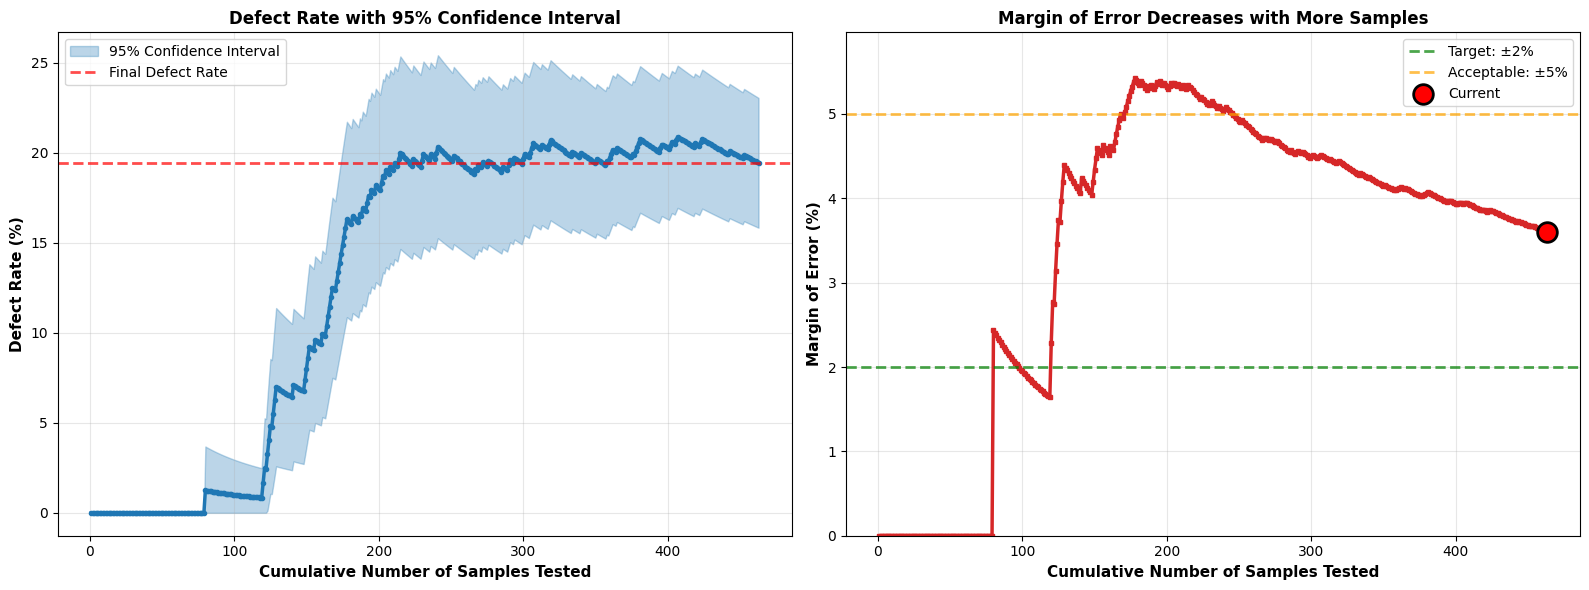

In [17]:
# Create main plot (2x1 grid without ax3)
plt.style.use('default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Defect Rate Over Time
ax1.plot(cumulative_n, cumulative_defect_rate, linewidth=2.5, color='#1f77b4', marker='o', markersize=3)
ax1.fill_between(cumulative_n, cumulative_lower_ci, cumulative_upper_ci, alpha=0.3, color='#1f77b4', label='95% Confidence Interval')
ax1.axhline(y=cumulative_defect_rate[-1], color='red', linestyle='--', linewidth=2, alpha=0.7, label='Final Defect Rate')
ax1.set_xlabel('Cumulative Number of Samples Tested', fontsize=11, fontweight='bold')
ax1.set_ylabel('Defect Rate (%)', fontsize=11, fontweight='bold')
ax1.set_title('Defect Rate with 95% Confidence Interval', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=10)

# Plot 2: Margin of Error Decreasing Over Time
ax2.plot(cumulative_n, cumulative_moe, linewidth=2.5, color='#d62728', marker='s', markersize=3)
ax2.axhline(y=2, color='green', linestyle='--', linewidth=2, alpha=0.7, label='Target: ±2%')
ax2.axhline(y=5, color='orange', linestyle='--', linewidth=2, alpha=0.7, label='Acceptable: ±5%')
ax2.scatter([cumulative_n[-1]], [cumulative_moe[-1]], color='red', s=200, marker='o', zorder=5, label='Current', edgecolors='black', linewidths=2)
ax2.set_xlabel('Cumulative Number of Samples Tested', fontsize=11, fontweight='bold')
ax2.set_ylabel('Margin of Error (%)', fontsize=11, fontweight='bold')
ax2.set_title('Margin of Error Decreases with More Samples', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=10)
ax2.set_ylim(0, max(cumulative_moe) * 1.1)

plt.tight_layout()
plt.savefig('data/cumulative_confidence_analysis.png', dpi=300, bbox_inches='tight')
print("✅ Main plot saved to: data/cumulative_confidence_analysis.png\n")
plt.show()


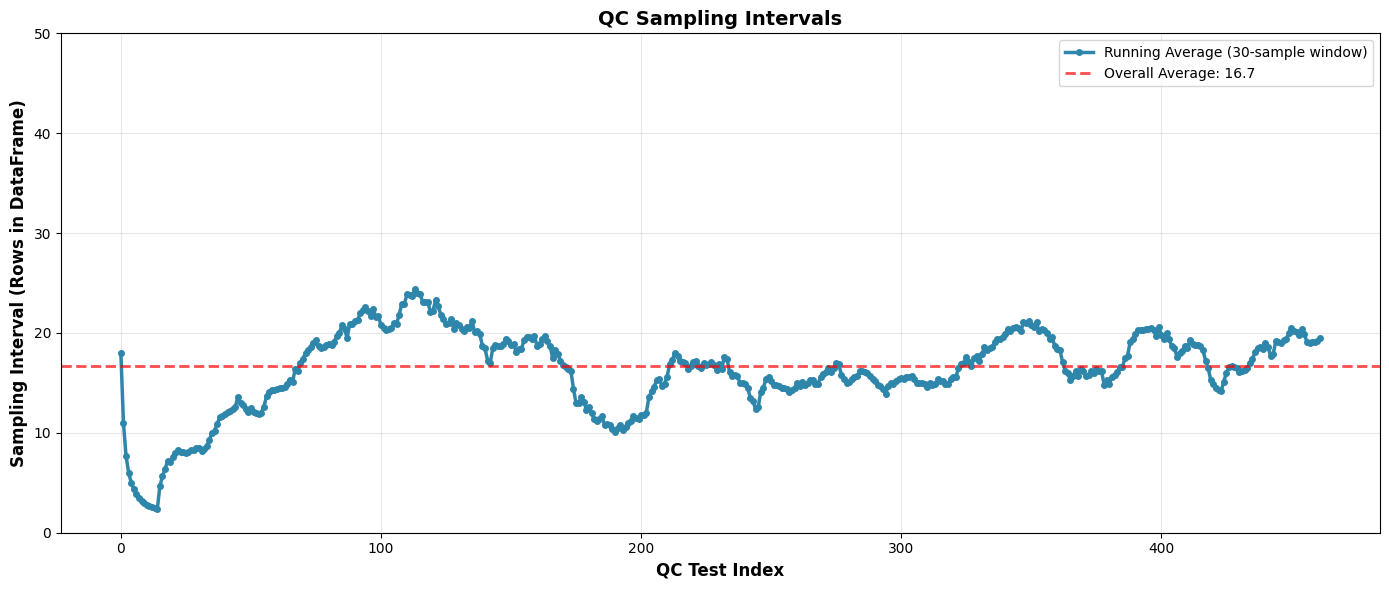

In [18]:
# Extract row positions from tested results in results_all_processed_df
test_row_positions = []

# Get the actual indices of tested rows
for idx in tested_df.index:
    test_row_positions.append(idx)

# Sort to ensure they're in order
test_row_positions.sort()

# Calculate distances between consecutive test row positions (actual rows in dataframe)
distances = [test_row_positions[i] - test_row_positions[i-1] for i in range(1, len(test_row_positions))]

window = 30
running_avg = [np.mean(distances[max(0, i-window):i+1]) for i in range(len(distances))]

# Create plot
plt.figure(figsize=(14, 6), facecolor='white')

plt.plot(running_avg, linewidth=2.5, marker='o', markersize=4, label=f'Running Average ({window}-sample window)', color='#2E86AB')
plt.axhline(y=np.mean(distances), color='red', linestyle='--', linewidth=2, label=f'Overall Average: {np.mean(distances):.1f}', alpha=0.7)

plt.xlabel('QC Test Index', fontsize=12, fontweight='bold')
plt.ylabel('Sampling Interval (Rows in DataFrame)', fontsize=12, fontweight='bold')
plt.title('QC Sampling Intervals', fontsize=14, fontweight='bold')
plt.ylim(0, 50)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
ax = plt.gca()
ax.set_facecolor('white')

plt.tight_layout()
plt.savefig('data/distance_between_tests.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [19]:


# Filter to only NOT tested electrodes
not_tested_df = electrode_analysis_df[electrode_analysis_df['Tested'] == False]

# Basic counts (only for not-tested)
total_electrodes = len(electrode_analysis_df)
not_tested_total = len(not_tested_df)
tested_total = len(electrode_analysis_df[electrode_analysis_df['Tested'] == True])

# Released and Scraped counts (only from not-tested electrodes)
released_count = (not_tested_df['Released'] == True).sum()
scraped_count = (not_tested_df['Scraped'] == True).sum()

# Calculate percentages
released_pct = (released_count / total_electrodes) * 100 if total_electrodes > 0 else 0
scraped_pct = (scraped_count / total_electrodes) * 100 if total_electrodes > 0 else 0
not_tested_pct_of_total = (not_tested_total / total_electrodes) * 100 if total_electrodes > 0 else 0

# Defect rate among not-tested (scraped / total not-tested)
defect_rate_not_tested = (scraped_count / not_tested_total) * 100 if not_tested_total > 0 else 0
success_rate_not_tested = (released_count / not_tested_total) * 100 if not_tested_total > 0 else 0


print("\n📊 OVERALL DATASET")
print(f"  Total electrodes in dataset: {total_electrodes}")
print(f"  Tested (DISCARDED): {tested_total} ({(tested_total/total_electrodes*100):.2f}%)")
print(f"  NOT tested (ANALYZED): {not_tested_total} ({not_tested_pct_of_total:.2f}%)")

print("\n⚠️ ANALYZING ONLY NOT-TESTED ELECTRODES")
print("(Tested electrodes go to trash regardless of outcome)")
print("\n📊 NOT-TESTED ELECTRODES BREAKDOWN")
print(f"  Released/Good: {released_count} ({released_pct:.2f}% of total, {success_rate_not_tested:.2f}% of not-tested)")
print(f"  Scraped/Bad: {scraped_count} ({scraped_pct:.2f}% of total, {defect_rate_not_tested:.2f}% of not-tested)")



📊 OVERALL DATASET
  Total electrodes in dataset: 7736
  Tested (DISCARDED): 463 (5.99%)
  NOT tested (ANALYZED): 7273 (94.01%)

⚠️ ANALYZING ONLY NOT-TESTED ELECTRODES
(Tested electrodes go to trash regardless of outcome)

📊 NOT-TESTED ELECTRODES BREAKDOWN
  Released/Good: 6162 (79.65% of total, 84.72% of not-tested)
  Scraped/Bad: 1111 (14.36% of total, 15.28% of not-tested)


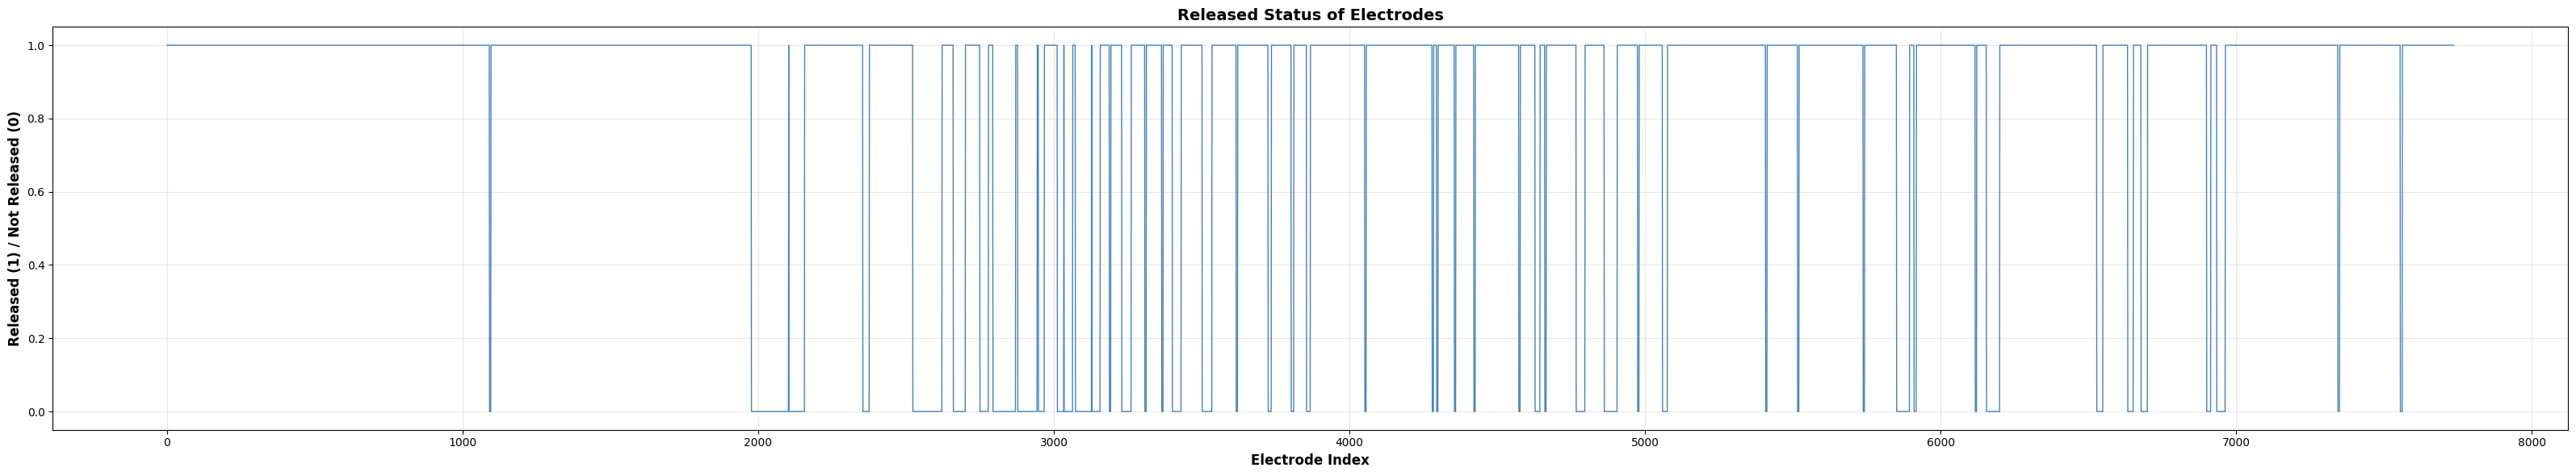

In [20]:
x_idx = [0]
y_idx = [1 if electrode_analysis_df.iloc[0]['Released'] else 0]


for idx, row in electrode_analysis_df.iterrows():
    if idx >= 0:
        x_idx.append(idx)
        y_idx.append(1 if row['Released'] else 0)

plt.figure(figsize=(32, 6), facecolor='white')
plt.plot(x_idx, y_idx, linestyle='-', color='steelblue', linewidth=1)
plt.xlabel('Electrode Index', fontsize=12, fontweight='bold')
plt.ylabel('Released (1) / Not Released (0)', fontsize=12, fontweight='bold')
plt.title('Released Status of Electrodes', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
ax = plt.gca()
ax.set_facecolor('white')
plt.tight_layout()
plt.show()


## BAD TESTED ELECTRODES & CLOSEST GOOD NEIGHBORS ANALYSIS

In [21]:

class Electrode:
    def __init__(self, id, electrode_number, is_tested, is_released, is_scraped):
        self.id = id
        self.electrode_number = electrode_number
        self.is_tested = is_tested
        self.is_released = is_released
        self.is_scraped = is_scraped


class BadElectrodeSequence:
    def __init__(self, electrode_map=None):
        self.bad_electrodes = []
        self.electrode_map = electrode_map  # Map from electrode name to index
        self.tested_bad_length = 0  # Electrodes you tested and found bad
        self.suspected_bad_length = 0    # Electrodes you suspect are bad (inference between good neighbors)
        self.good_electrode_before = None
        self.good_electrode_after = None

    def __add__(self, other):
        if isinstance(other, Electrode):
            self.bad_electrodes.append(other)
            # Sort bad electrodes by ID after adding
            self.bad_electrodes.sort(key=lambda e: e.id)
            # Calculate tested_bad_length based on electrode indices
            self._update_tested_bad_length()
        return self

    def _update_tested_bad_length(self):
        """Calculate tested_bad_length using pre-built electrode map."""
        if not self.bad_electrodes or self.electrode_map is None:
            self.tested_bad_length = len(self.bad_electrodes)
            return

        first_electrode = self.bad_electrodes[0].id
        last_electrode = self.bad_electrodes[-1].id

        first_idx = self.electrode_map.get(first_electrode)
        last_idx = self.electrode_map.get(last_electrode)

        if first_idx is not None and last_idx is not None:
            self.tested_bad_length = last_idx - first_idx + 1
        else:
            self.tested_bad_length = len(self.bad_electrodes)

    def _update_suspected_bad_length(self):
        """Calculate suspected_bad_length from good_electrode_before to good_electrode_after."""
        if self.good_electrode_before is None or self.good_electrode_after is None:
            self.suspected_bad_length = self.tested_bad_length
            return

        before_idx = self.electrode_map.get(self.good_electrode_before.id)
        after_idx = self.electrode_map.get(self.good_electrode_after.id)

        if before_idx is not None and after_idx is not None:
            self.suspected_bad_length = after_idx - before_idx - 1
        else:
            self.suspected_bad_length = self.tested_bad_length



In [22]:
# OPTIMIZED: Pre-build electrode lookup map and cache arrays for O(1) lookups
electrode_to_idx = {row['Electrode']: idx for idx, row in electrode_analysis_df.iterrows()}
df_len = len(electrode_analysis_df)

# Cache arrays for fast access (avoid iloc calls)
tested_arr = electrode_analysis_df['Tested'].values
scraped_arr = electrode_analysis_df['Scraped'].values
released_arr = electrode_analysis_df['Released'].values
electrode_arr = electrode_analysis_df['Electrode'].values

bad_electrode_sequences = []
last_good_electrode_num = -1

for idx in range(df_len):
    # Skip if already processed
    if idx > 0 and last_good_electrode_num >= extract_number(electrode_arr[idx]):
        continue

    if tested_arr[idx] and scraped_arr[idx]:
        electrode_name = electrode_arr[idx]
        bad_electrode_sequence = BadElectrodeSequence(electrode_to_idx)
        bad_electrode_sequence + Electrode(electrode_name, extract_number(electrode_name), tested_arr[idx], released_arr[idx], scraped_arr[idx])

        # Loop back until we find a released one
        back_idx = idx - 1
        while back_idx >= 0:
            if tested_arr[back_idx] and released_arr[back_idx]:
                bad_electrode_sequence.good_electrode_before = Electrode(electrode_arr[back_idx], extract_number(electrode_arr[back_idx]), tested_arr[back_idx], released_arr[back_idx], scraped_arr[back_idx])
                break
            if tested_arr[back_idx] and scraped_arr[back_idx]:
                bad_electrode_sequence + Electrode(electrode_arr[back_idx], extract_number(electrode_arr[back_idx]), tested_arr[back_idx], released_arr[back_idx], scraped_arr[back_idx])
            back_idx -= 1

        # Loop forward until we find a released one
        forward_idx = idx + 1
        while forward_idx < df_len:
            if tested_arr[forward_idx] and released_arr[forward_idx]:
                bad_electrode_sequence.good_electrode_after = Electrode(electrode_arr[forward_idx], extract_number(electrode_arr[forward_idx]), tested_arr[forward_idx], released_arr[forward_idx], scraped_arr[forward_idx])
                last_good_electrode_num = extract_number(electrode_arr[forward_idx])
                break
            if tested_arr[forward_idx] and scraped_arr[forward_idx]:
                bad_electrode_sequence + Electrode(electrode_arr[forward_idx], extract_number(electrode_arr[forward_idx]), tested_arr[forward_idx], released_arr[forward_idx], scraped_arr[forward_idx])
            forward_idx += 1

        # Update suspected_bad_length now that good electrodes are set
        bad_electrode_sequence._update_suspected_bad_length()

        print(f"Bad Electrode range saved: {bad_electrode_sequence.good_electrode_before.id} - {bad_electrode_sequence.good_electrode_after.id}")
        bad_electrode_sequences.append(bad_electrode_sequence)


Bad Electrode range saved: B2092 - B2125
Bad Electrode range saved: B3080 - B3255
Bad Electrode range saved: B3255 - B3322
Bad Electrode range saved: B3578 - B3601
Bad Electrode range saved: B3753 - B3860
Bad Electrode range saved: B3900 - B3942
Bad Electrode range saved: B3990 - B4020
Bad Electrode range saved: B4038 - B4118
Bad Electrode range saved: B4129 - B4231
Bad Electrode range saved: B4234 - B4259
Bad Electrode range saved: B4302 - B4325
Bad Electrode range saved: B4325 - B4379
Bad Electrode range saved: B4388 - B4445
Bad Electrode range saved: B4445 - B4474
Bad Electrode range saved: B4501 - B4525
Bad Electrode range saved: B4563 - B4608
Bad Electrode range saved: B4608 - B4680
Bad Electrode range saved: B4708 - B4755
Bad Electrode range saved: B4771 - B4810
Bad Electrode range saved: B4872 - B4927
Bad Electrode range saved: B5000 - B5025
Bad Electrode range saved: B5168 - B5202
Bad Electrode range saved: B5312 - B5326
Bad Electrode range saved: B5365 - B5385
Bad Electrode ra

In [23]:
for bad_electrode_sequence in bad_electrode_sequences:
    print(f"\n=== BAD ELECTRODE SEQUENCE ===")
    print(f"Tested Bad Length: {bad_electrode_sequence.tested_bad_length}")
    print(f"Suspected Bad Length: {bad_electrode_sequence.suspected_bad_length}")
    print(f"Good electrode before: {bad_electrode_sequence.good_electrode_before.id if bad_electrode_sequence.good_electrode_before else 'None'}")
    print(f"Good electrode after: {bad_electrode_sequence.good_electrode_after.id if bad_electrode_sequence.good_electrode_after else 'None'}")
    print("Bad electrodes in this sequence:")
    for bad in bad_electrode_sequence.bad_electrodes:
        print(f"  - {bad.id}")



=== BAD ELECTRODE SEQUENCE ===
Tested Bad Length: 1
Suspected Bad Length: 32
Good electrode before: B2092
Good electrode after: B2125
Bad electrodes in this sequence:
  - B2110

=== BAD ELECTRODE SEQUENCE ===
Tested Bad Length: 120
Suspected Bad Length: 139
Good electrode before: B3080
Good electrode after: B3255
Bad electrodes in this sequence:
  - B3095
  - B3135
  - B3160
  - B3233
  - B3234
  - B3248

=== BAD ELECTRODE SEQUENCE ===
Tested Bad Length: 42
Suspected Bad Length: 53
Good electrode before: B3255
Good electrode after: B3322
Bad electrodes in this sequence:
  - B3259
  - B3282
  - B3313

=== BAD ELECTRODE SEQUENCE ===
Tested Bad Length: 1
Suspected Bad Length: 22
Good electrode before: B3578
Good electrode after: B3601
Bad electrodes in this sequence:
  - B3591

=== BAD ELECTRODE SEQUENCE ===
Tested Bad Length: 58
Suspected Bad Length: 99
Good electrode before: B3753
Good electrode after: B3860
Bad electrodes in this sequence:
  - B3771
  - B3796
  - B3810
  - B3834

=== 


=== DISTRIBUTION STATISTICS ===
Tested Bad Length (confirmed bad electrodes only):
  Mean: 11.42
  Std Dev: 20.31
  Min: 1
  Max: 120

Suspected Bad Length:
  Mean: 37.24
  Std Dev: 23.48
  Min: 6
  Max: 139

✅ Distribution plots saved to: data/electrode_bad_good_neighbors_analysis.png



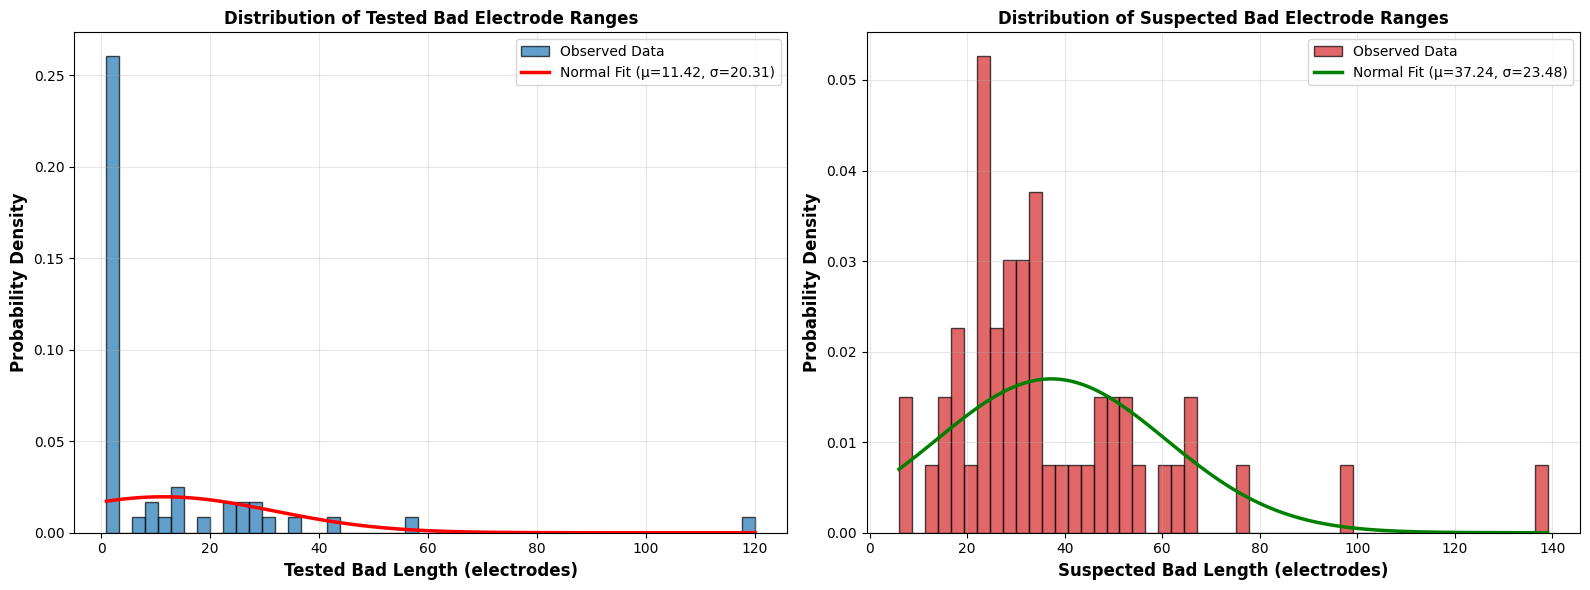

In [24]:
# Extract range data for distribution analysis

tested_bad_lengths = [seq.tested_bad_length for seq in bad_electrode_sequences]
suspected_bad_lengths = [seq.suspected_bad_length for seq in bad_electrode_sequences]

print(f"\n=== DISTRIBUTION STATISTICS ===")
print(f"Tested Bad Length (confirmed bad electrodes only):")
print(f"  Mean: {np.mean(tested_bad_lengths):.2f}")
print(f"  Std Dev: {np.std(tested_bad_lengths):.2f}")
print(f"  Min: {np.min(tested_bad_lengths)}")
print(f"  Max: {np.max(tested_bad_lengths)}")

print(f"\nSuspected Bad Length:")
print(f"  Mean: {np.mean(suspected_bad_lengths):.2f}")
print(f"  Std Dev: {np.std(suspected_bad_lengths):.2f}")
print(f"  Min: {np.min(suspected_bad_lengths)}")
print(f"  Max: {np.max(suspected_bad_lengths)}")

# Create two plots with normal distribution fits
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
bins = 50
# Plot 1: Tested Bad Length Distribution
ax1.hist(tested_bad_lengths, bins=bins, density=True, alpha=0.7, color='#1f77b4', edgecolor='black', label='Observed Data')

# Fit normal distribution to tested_bad_length
mu1, sigma1 = np.mean(tested_bad_lengths), np.std(tested_bad_lengths)
x1 = np.linspace(min(tested_bad_lengths), max(tested_bad_lengths), 100)
ax1.plot(x1, stats.norm.pdf(x1, mu1, sigma1), 'r-', linewidth=2.5, label=f'Normal Fit (μ={mu1:.2f}, σ={sigma1:.2f})')

ax1.set_xlabel('Tested Bad Length (electrodes)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Probability Density', fontsize=12, fontweight='bold')
ax1.set_title('Distribution of Tested Bad Electrode Ranges', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Plot 2: Suspected Bad Length Distribution
ax2.hist(suspected_bad_lengths, bins=bins, density=True, alpha=0.7, color='#d62728', edgecolor='black', label='Observed Data')

# Fit normal distribution to suspected_bad_length
mu2, sigma2 = np.mean(suspected_bad_lengths), np.std(suspected_bad_lengths)
x2 = np.linspace(min(suspected_bad_lengths), max(suspected_bad_lengths), 100)
ax2.plot(x2, stats.norm.pdf(x2, mu2, sigma2), 'g-', linewidth=2.5, label=f'Normal Fit (μ={mu2:.2f}, σ={sigma2:.2f})')

ax2.set_xlabel('Suspected Bad Length (electrodes)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Probability Density', fontsize=12, fontweight='bold')
ax2.set_title('Distribution of Suspected Bad Electrode Ranges', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/electrode_bad_good_neighbors_analysis.png', dpi=300, bbox_inches='tight')
print("\n✅ Distribution plots saved to: data/electrode_bad_good_neighbors_analysis.png\n")
plt.show()


# SIMPLE STATISTICS PLOT

✅ Plot saved to: data/bad_sequences_statistics_v2.png


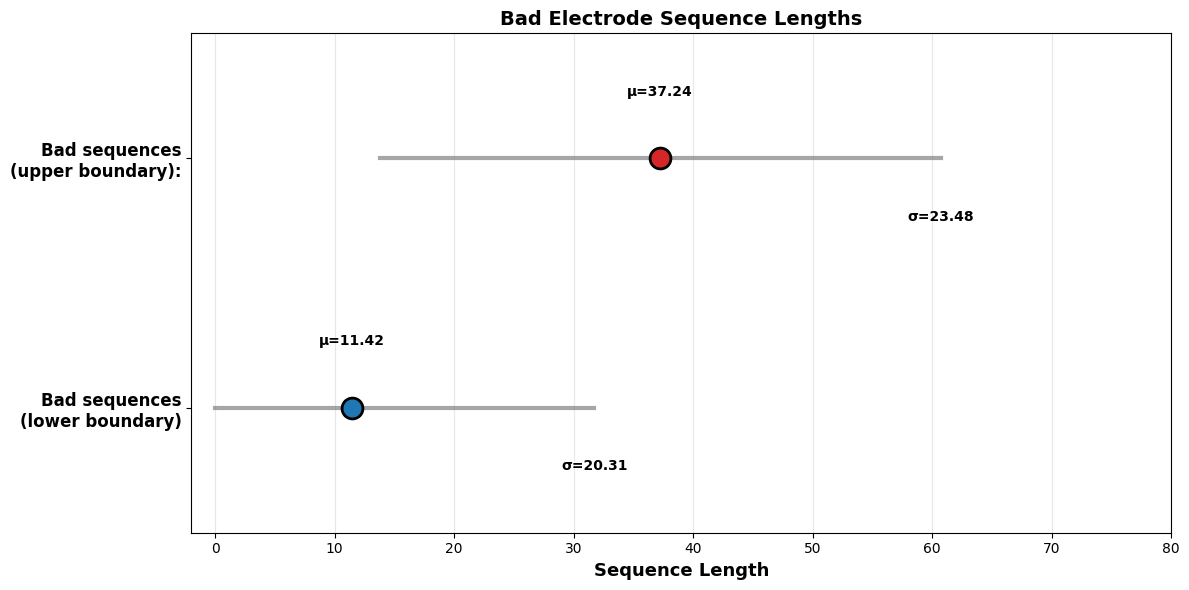

In [27]:
fig, ax = plt.subplots(figsize=(12, 6))

# Data
categories = ['Bad sequences\n(lower boundary)', 'Bad sequences\n(upper boundary):']
means = [11.42, 37.24]
stds = [20.31, 23.48]
mins = [1, 6]
maxs = [120, 139]

y_pos = [0, 1]
colors = ['#1f77b4', '#d62728']

# Draw lines from min to max for each category (now horizontal)
for i, (y, mean, color, std) in enumerate(zip(y_pos, means, colors, stds)):

    # Std dev range as horizontal line (clamp lower bound at 0)
    lower_bound = max(0, mean - std)  # Don't go below 0
    ax.plot([lower_bound, mean + std], [y, y], linewidth=3, color='gray', alpha=0.7)

    # Mean point (drawn last so it's on top)
    ax.plot(mean, y, marker='o', markersize=15, color=color, zorder=5, markeredgecolor='black', markeredgewidth=2)

# Add value labels (only mean and std)
labels_data = [
    (11.42, 0.25, 'μ=11.42'),
    (31.73, -0.25, 'σ=20.31'),
    (37.24, 1.25, 'μ=37.24'),
    (60.72, 0.75, 'σ=23.48'),
]

for x, y, label in labels_data:
    ax.text(x, y, label, fontsize=10, fontweight='bold', ha='center')

ax.set_yticks(y_pos)
ax.set_yticklabels(categories, fontsize=12, fontweight='bold')
ax.set_xlabel('Sequence Length', fontsize=13, fontweight='bold')
ax.set_title('Bad Electrode Sequence Lengths', fontsize=14, fontweight='bold')
ax.set_xlim(-2, 80)
ax.grid(True, alpha=0.3, axis='x')
ax.set_ylim(-0.5, 1.5)

plt.tight_layout()
plt.savefig('data/bad_sequences_statistics_v2.png', dpi=300, bbox_inches='tight')
print("✅ Plot saved to: data/bad_sequences_statistics_v2.png")
plt.show()
